# Dataset Understanding

## Project: Customer Financial Profile Analysis

### Objective
Understand the structure, characteristics, distributions, and data quality of the customer financial dataset before performing data cleaning.

### Business Context
The dataset contains customer demographic information, income, credit scores, loan amounts, savings balances, employment status, and recorded financial risk levels.

### Analysis Goals
1. Inspect the dataset structure.
2. Understand column names and data types.
3. Examine sample records and summary statistics.
4. Check missing values and duplicate records.
5. Investigate unique values and categorical distributions.
6. Identify potential data quality issues.
7. Prepare a data dictionary for subsequent analysis.

### Tools
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn

### Important Note
The original dataset will remain unchanged. Data cleaning will be performed in Phase 3 after this inspection is complete.

In [4]:
import pandas as pd
import numpy as np
from pathlib import Path

# Locate the project root from the notebook's current working directory
cwd = Path.cwd()

if cwd.name == "notebooks":
    project_root = cwd.parent
else:
    project_root = cwd

# Define the original dataset path
file_path = (
    project_root
    / "data"
    / "raw"
    / "Customer_Financial_Profile_Dataset.csv"
)

# Verify the file exists before loading it
print("Project root:", project_root)
print("Dataset path:", file_path)
print("File exists:", file_path.exists())

if not file_path.exists():
    raise FileNotFoundError(
        f"Dataset not found: {file_path}. "
        "Check the filename and data/raw folder."
    )

# Load the original CSV
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")


Project root: e:\Customer Financial Profile Analysis
Dataset path: e:\Customer Financial Profile Analysis\data\raw\Customer_Financial_Profile_Dataset.csv
File exists: True
Dataset loaded successfully!


In [4]:
df.head()

df.tail()

print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Total cells:", df.size)

print("Column names:")
for column in df.columns:
    print(column)

print("Duplicate column names:", df.columns.duplicated().sum())

df.info()

print(df.dtypes)

Number of rows: 1000
Number of columns: 9
Total cells: 9000
Column names:
Customer_ID
Age
Gender
Annual_Income
Credit_Score
Loan_Amount
Savings_Balance
Employment_Status
Risk_Level
Duplicate column names: 0
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   Customer_ID        1000 non-null   str  
 1   Age                1000 non-null   int64
 2   Gender             1000 non-null   str  
 3   Annual_Income      1000 non-null   int64
 4   Credit_Score       1000 non-null   int64
 5   Loan_Amount        1000 non-null   int64
 6   Savings_Balance    1000 non-null   int64
 7   Employment_Status  1000 non-null   str  
 8   Risk_Level         1000 non-null   str  
dtypes: int64(5), str(4)
memory usage: 70.4 KB
Customer_ID            str
Age                  int64
Gender                 str
Annual_Income        int64
Credit_Score         int64
Loan_Amount

In [5]:
# Check missing values

missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (
        df.isna().mean() * 100
    ).round(2)
})

missing_summary

print("Total missing values:", df.isna().sum().sum())

Total missing values: 0


In [7]:
# Check duplicate records

print("Exact duplicate rows:", df.duplicated().sum())
print(
    "Duplicate Customer_ID values:",
    df["Customer_ID"].duplicated().sum()
)

duplicate_ids = df[
    df["Customer_ID"].duplicated(keep=False)
].sort_values("Customer_ID")

duplicate_ids

Exact duplicate rows: 0
Duplicate Customer_ID values: 0


Empty DataFrame
Columns: [Customer_ID, Age, Gender, Annual_Income, Credit_Score, Loan_Amount, Savings_Balance, Employment_Status, Risk_Level]
Index: []

In [11]:
# Generate summary statistics

df.describe()


               Age  Annual_Income  Credit_Score   Loan_Amount  Savings_Balance
count  1000.000000    1000.000000   1000.000000   1000.000000      1000.000000
mean     43.617000   82136.893000    576.083000  24185.562000     98732.278000
std      14.981414   38911.251316    157.206221  14476.572356     59720.500247
min      18.000000   15012.000000    302.000000    198.000000       153.000000
25%      31.000000   47256.750000    440.750000  11348.500000     43070.500000
50%      43.000000   82367.500000    569.000000  23943.500000    100097.000000
75%      57.000000  116115.000000    711.250000  36844.750000    150810.000000
max      69.000000  149971.000000    850.000000  49839.000000    199822.000000

In [12]:
financial_columns = [
    "Annual_Income",
    "Credit_Score",
    "Loan_Amount",
    "Savings_Balance"
]

df[financial_columns].describe().T

                  count       mean           std      min       25%       50%  \
Annual_Income    1000.0  82136.893  38911.251316  15012.0  47256.75   82367.5   
Credit_Score     1000.0    576.083    157.206221    302.0    440.75     569.0   
Loan_Amount      1000.0  24185.562  14476.572356    198.0  11348.50   23943.5   
Savings_Balance  1000.0  98732.278  59720.500247    153.0  43070.50  100097.0   

                       75%       max  
Annual_Income    116115.00  149971.0  
Credit_Score        711.25     850.0  
Loan_Amount       36844.75   49839.0  
Savings_Balance  150810.00  199822.0  

In [17]:
# Understand categorical columns

categorical_columns = [
    "Gender",
    "Employment_Status",
    "Risk_Level"
]

for column in categorical_columns:
    print(f"\n--- {column} ---")
    print(df[column].value_counts(dropna=False))

for column in categorical_columns:
    print(f"\n--- {column}: Percentage ---")
    print(
        (df[column].value_counts(normalize=True, dropna=False) * 100)
        .round(2)
    )



--- Gender ---
Gender
Female    523
Male      477
Name: count, dtype: int64

--- Employment_Status ---
Employment_Status
Unemployed       336
Employed         334
Self-Employed    330
Name: count, dtype: int64

--- Risk_Level ---
Risk_Level
Medium    341
High      334
Low       325
Name: count, dtype: int64

--- Gender: Percentage ---
Gender
Female    52.3
Male      47.7
Name: proportion, dtype: float64

--- Employment_Status: Percentage ---
Employment_Status
Unemployed       33.6
Employed         33.4
Self-Employed    33.0
Name: proportion, dtype: float64

--- Risk_Level: Percentage ---
Risk_Level
Medium    34.1
High      33.4
Low       32.5
Name: proportion, dtype: float64


In [20]:
# Investigate numeric ranges

numeric_columns = [
    "Age",
    "Annual_Income",
    "Credit_Score",
    "Loan_Amount",
    "Savings_Balance"
]

range_summary = pd.DataFrame({
    "Minimum": df[numeric_columns].min(),
    "Maximum": df[numeric_columns].max(),
    "Unique_Values": df[numeric_columns].nunique()
})

range_summary



                 Minimum  Maximum  Unique_Values
Age                   18       69             52
Annual_Income      15012   149971            999
Credit_Score         302      850            458
Loan_Amount          198    49839            989
Savings_Balance      153   199822            996

In [21]:
# Check for negative financial values

financial_columns = [
    "Annual_Income",
    "Loan_Amount",
    "Savings_Balance"
]

negative_counts = (
    df[financial_columns].lt(0).sum()
    .rename("Negative_Value_Count")
)

negative_counts

Annual_Income      0
Loan_Amount        0
Savings_Balance    0
Name: Negative_Value_Count, dtype: int64

In [22]:
# Check the number of unique values

unique_summary = pd.DataFrame({
    "Unique_Values": df.nunique(dropna=False),
    "Data_Type": df.dtypes.astype(str)
})

unique_summary

                   Unique_Values Data_Type
Customer_ID                 1000       str
Age                           52     int64
Gender                         2       str
Annual_Income                999     int64
Credit_Score                 458     int64
Loan_Amount                  989     int64
Savings_Balance              996     int64
Employment_Status              3       str
Risk_Level                     3       str

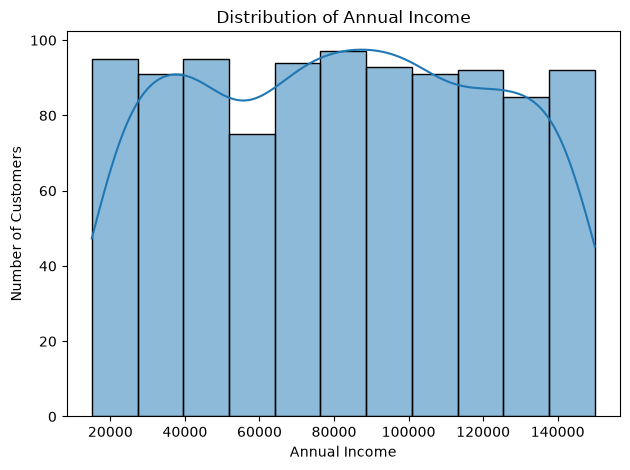

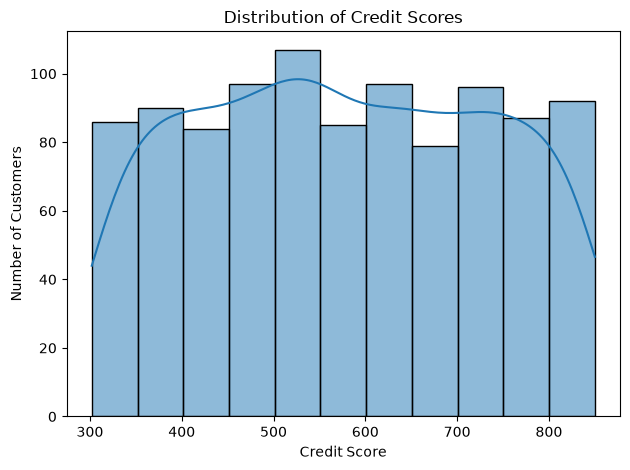

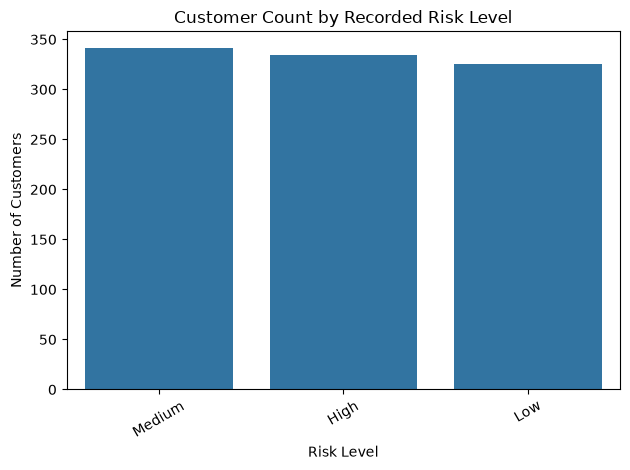

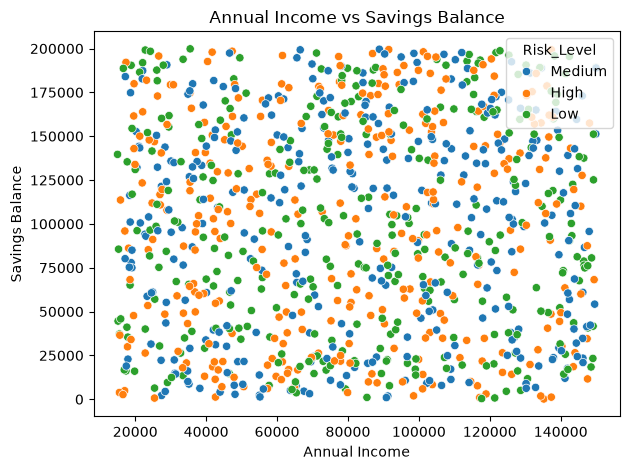

In [23]:
# Visualize the financial distributions

# Income distribution

import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(data=df, x="Annual_Income", kde=True)
plt.title("Distribution of Annual Income")
plt.xlabel("Annual Income")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# Credit score distribution

sns.histplot(data=df, x="Credit_Score", kde=True)
plt.title("Distribution of Credit Scores")
plt.xlabel("Credit Score")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# Risk-level distribution

sns.countplot(data=df, x="Risk_Level")
plt.title("Customer Count by Recorded Risk Level")
plt.xlabel("Risk Level")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Income compared with savings

sns.scatterplot(
    data=df,
    x="Annual_Income",
    y="Savings_Balance",
    hue="Risk_Level"
)
plt.title("Annual Income vs Savings Balance")
plt.xlabel("Annual Income")
plt.ylabel("Savings Balance")
plt.tight_layout()
plt.show()



In [24]:
# Run and save the complete notebook

inspection_summary = {
    "row_count": len(df),
    "column_count": len(df.columns),
    "duplicate_column_names": int(df.columns.duplicated().sum()),
    "missing_values": int(df.isna().sum().sum()),
    "duplicate_rows": int(df.duplicated().sum()),
    "unique_customer_ids": int(df["Customer_ID"].nunique())
}

pd.Series(inspection_summary, name="Value")

summary_df = pd.DataFrame(
    inspection_summary.items(),
    columns=["Metric", "Value"]
)

output_path = (
    project_root / "reports" / "dataset_inspection_summary.csv"
)

summary_df.to_csv(output_path, index=False)

print("Summary saved to:", output_path)

Summary saved to: e:\Customer Financial Profile Analysis\reports\dataset_inspection_summary.csv


## Conclusion — Dataset Understanding

### Summary

In this phase, we successfully loaded and explored the Customer Financial Profile dataset using Python and Pandas. We examined the dataset's structure, column names, data types, statistical summaries, categorical distributions, and data quality.

### Key Findings

- **Dataset size:** 1,000 customer records and 9 columns.
- **Customer identification:** `Customer_ID` uniquely identifies each customer.
- **Customer demographics:** The dataset contains information about customer age and gender.
- **Financial information:** Annual income, credit score, loan amount, and savings balance are available for analysis.
- **Employment information:** Customers are classified as Employed, Self-Employed, or Unemployed.
- **Risk classification:** Each customer has a Low, Medium, or High risk label.
- **Data quality:** Initial inspection found no missing values, exact duplicate rows, or duplicate customer IDs.
- **Data types:** Numeric and categorical columns were identified for further analysis.

### Business Value

Understanding the dataset helps us identify the information available for customer financial analysis. These findings establish a foundation for data cleaning, exploratory data analysis (EDA), SQL business analysis, and Power BI dashboard development.

### Next Steps

In the next phase, **Data Cleaning and Validation**, we will:

1. Load the original dataset from the `data/raw/` folder.
2. Validate column names and data types.
3. Check missing values, duplicate records, and invalid values.
4. Standardize text values and validate customer IDs.
5. Save the validated dataset to `data/processed/Customer_Financial_Profile_Cleaned.csv`.
6. Verify that the cleaned dataset is ready for exploratory data analysis.

### Final Status

**Dataset Understanding: Completed**

The dataset has been inspected, its structure and data quality have been reviewed, and the initial findings have been documented.

**Note:** The existing `Risk_Level` column will be treated as a supplied classification for descriptive analysis. This project does not establish that the labels predict actual loan defaults or prove causal relationships.